Inicializo las librerias que voy a usar

In [84]:
import cv2
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.ticker import PercentFormatter
import numpy as np

DECLARO LAS FUNCIONES QUE VOY A USAR





Funcion para pasar de RGB a YIQ

In [85]:
def RGBaYIQ(imagen):
       M = np.array([[0.299, 0.587, 0.114],
                  [0.596, -0.275, -0.321],
                  [0.212, -0.523, 0.311]])

       R=imagen[:,:,2]
       G=imagen[:,:,1]
       B=imagen[:,:,0]

       alto,ancho=R.shape # obtengo las dimensiones de la matriz

       # Reorganizar la imagen: (alto*ancho, 3)
       rgb = np.stack([R, G, B],axis=-1).reshape(-1, 3) #une secuencias de matrices, 3 columnas y las filas las determina numpy por eso el  -1
       yiq = np.dot(rgb, M.T)

       # Volver a la forma original
       yiq = yiq.reshape(alto, ancho, 3)

       Y=yiq[:,:,0]
       I=yiq[:,:,1]
       Q=yiq[:,:,2]

       return Y,I,Q

Funcion para pasar de YIQ a RGB

In [86]:
def YIQaRGB(Y,I,Q):
          matriz=np.array([[1, 0.9663, 0.6210],
                          [1, -0.2721, -0.6474],
                          [1, -1.1070, 1.7046]])

          alto, ancho = Y.shape
          yiq = np.stack([Y, I, Q], axis=-1).reshape(-1, 3)# Reorganizar en (alto*ancho, 3)
          rgb = np.dot(yiq, matriz.T)
          rgb = rgb.reshape(alto, ancho, 3)
          rgb = np.clip(rgb, 0, 1) # limita los valores entre 0 y 1

          return (rgb*255).astype(np.uint8)

Funcion para normalizar la imagen

In [87]:
def normalizarImagen(imagen):
  return imagen/255

Funcion para mostrar el histograma
https://matplotlib.org/stable/gallery/statistics/hist.html

In [88]:
def mostrar_histograma(imagen):
       datos=imagen.flatten()   #paso de una matriz a un arreglo
       N,bins,patches=plt.hist(datos,bins=60,range=(0,1))  #bin=cant de barras

       #Normalizar las alturas (N) para aplicar colores
       fracs = N / N.max()
       norm = colors.Normalize(fracs.min(), fracs.max())
       # Aplicar colores usando el mapa 'viridis'
       for thisfrac, thispatch in zip(fracs, patches):
            color = plt.cm.viridis(norm(thisfrac))   #usa el colormap viridis
            thispatch.set_facecolor(color)

       plt.title("Histograma")
       plt.xlabel("Luminancia")
       plt.ylabel("Frecuencia")
       #plt.hist(datos,bins=50,range=(0,1)) # NO lo pongo porque llama a plt.hist para superponerlo con la anterior
       #plt.show()



Funcion Clamping

In [89]:
def Clamping(imagen):
    return np.clip(1.5*imagen,0,1)

Funcion Lineal a trozos

In [90]:
def Lineal_trozos(imagen):
  Ymin=0.2
  Ymax=0.9
  img_trozos=(imagen-Ymin)/(Ymax-Ymin)
  img_trozos=np.clip(img_trozos,0,1)
  return img_trozos


Funcion Filtro raiz

In [91]:
def filtro_raiz(imagen):
  return np.sqrt(imagen)


Funcion filtro cuadrado

In [92]:
def filtro_potencia(imagen,n):
  imagen=imagen**n
  return imagen

EJECUTO LAS FUNCIONES CREADAS

En la primera fila muestro la imagen real y su histograma, el la segunda fila la funcion clamping y su histograma que seria la matriz imagen multiplicada por una constante imagen'=cte*imagen





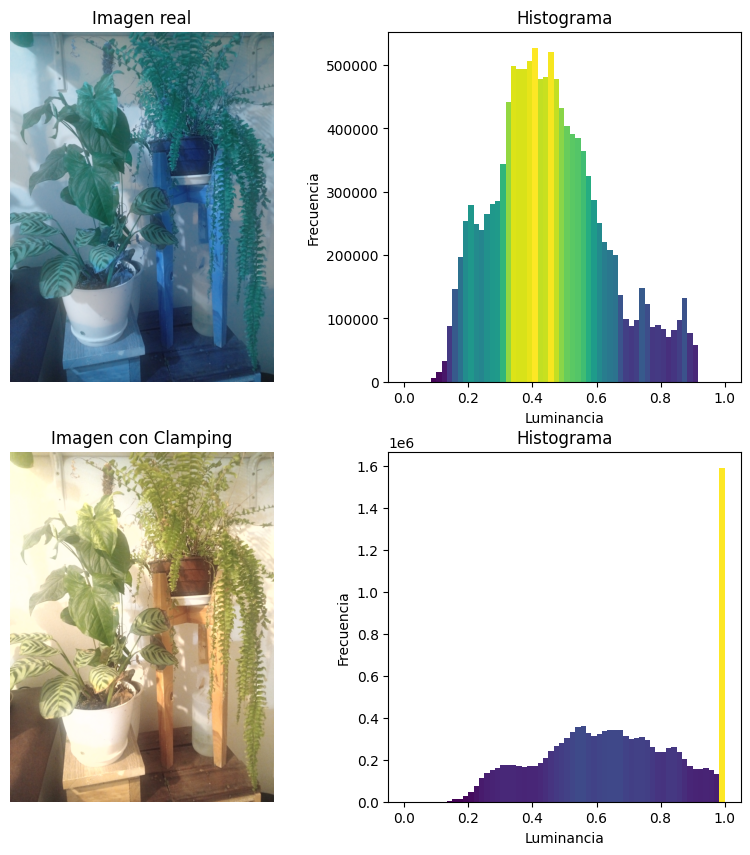

In [93]:
mi_imagen=normalizarImagen(cv2.imread("imagen1.jpg"))
y,i,q=RGBaYIQ(mi_imagen)

# copia de una imagen
y1,i2,q2=RGBaYIQ(mi_imagen.copy())
imagen_copy=Clamping(y1)
#imagen a color

imagen_copy_color=YIQaRGB(imagen_copy,i2,q2)
filas=2
columnas=2

plt.figure(figsize=(10,10))

plt.subplot(filas,columnas,1)
plt.axis("off")
plt.title("Imagen real")
plt.imshow(mi_imagen,cmap="gray")

plt.subplot(filas,columnas,2)
mostrar_histograma(y)

plt.subplot(filas,columnas,3)
plt.axis("off")
plt.title("Imagen con Clamping")
#plt.imshow(imagen_copy,cmap="gray") #descomentar si la imagen lo queres en escala de grises y comenta la linea siguiente
plt.imshow(imagen_copy_color)
plt.subplot(filas,columnas,4)
mostrar_histograma(imagen_copy)

plt.show()




Aplico la funcion Lineal a trozos y muestro la imagen a color y el histograma de "Y"

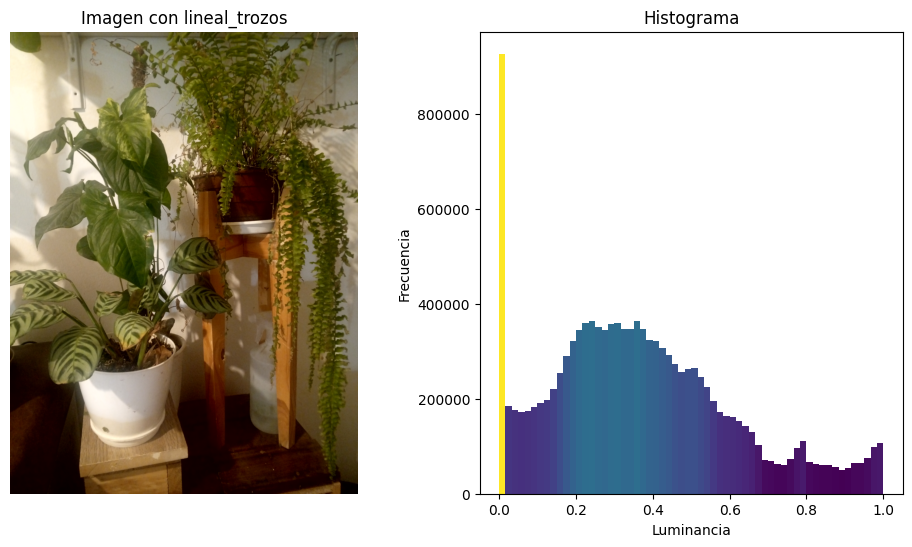

In [94]:

imagen_copy2=Lineal_trozos(y1)
imagen_copy_color2=YIQaRGB(imagen_copy2,i2,q2)

plt.figure(figsize=(12,6))

plt.subplot(1,columnas,1)
plt.axis("off")
plt.title("Imagen con lineal_trozos")
#plt.imshow(imagen_copy2,cmap="gray")
plt.imshow(imagen_copy_color2)
plt.subplot(1,columnas,2)
mostrar_histograma(imagen_copy2)

plt.show()

Aplico la funcion a filtro raiz ,muestro la imagen a color y el histograma de "Y"

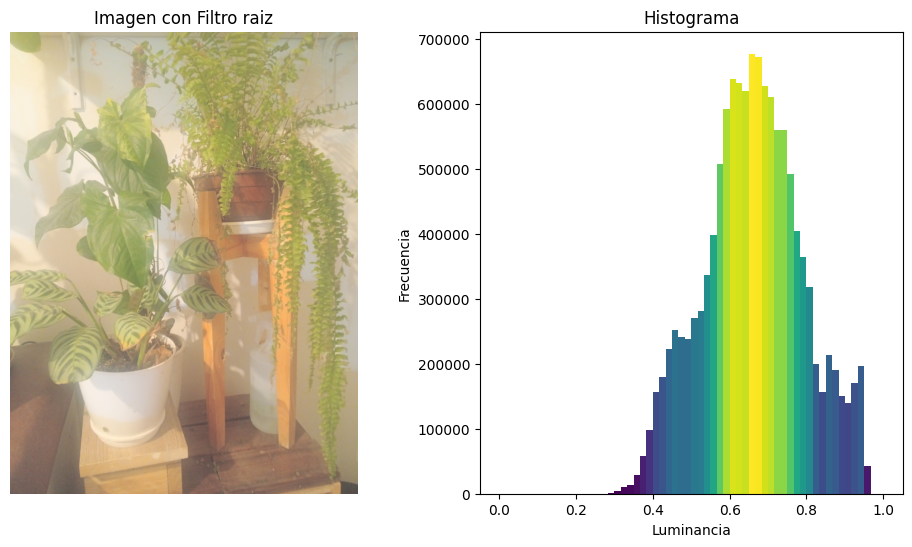

In [95]:

imagen_copy3=filtro_raiz(y1)
imagen_copy_color3=YIQaRGB(imagen_copy3,i2,q2)

plt.figure(figsize=(12,6))
plt.subplot(1,columnas,1)
plt.axis("off")
plt.title("Imagen con Filtro raiz")
#plt.imshow(imagen_copy3,cmap="gray")
plt.imshow(imagen_copy_color3)

plt.subplot(1,columnas,2)
mostrar_histograma(imagen_copy3)

plt.show()

Aplico la funcion de potencia para ver el fitro cuadrado ,y aprobechando la funcion veo como es la respuesta con otro exponente.
Muestro la imagen a color y el histograma de "Y"

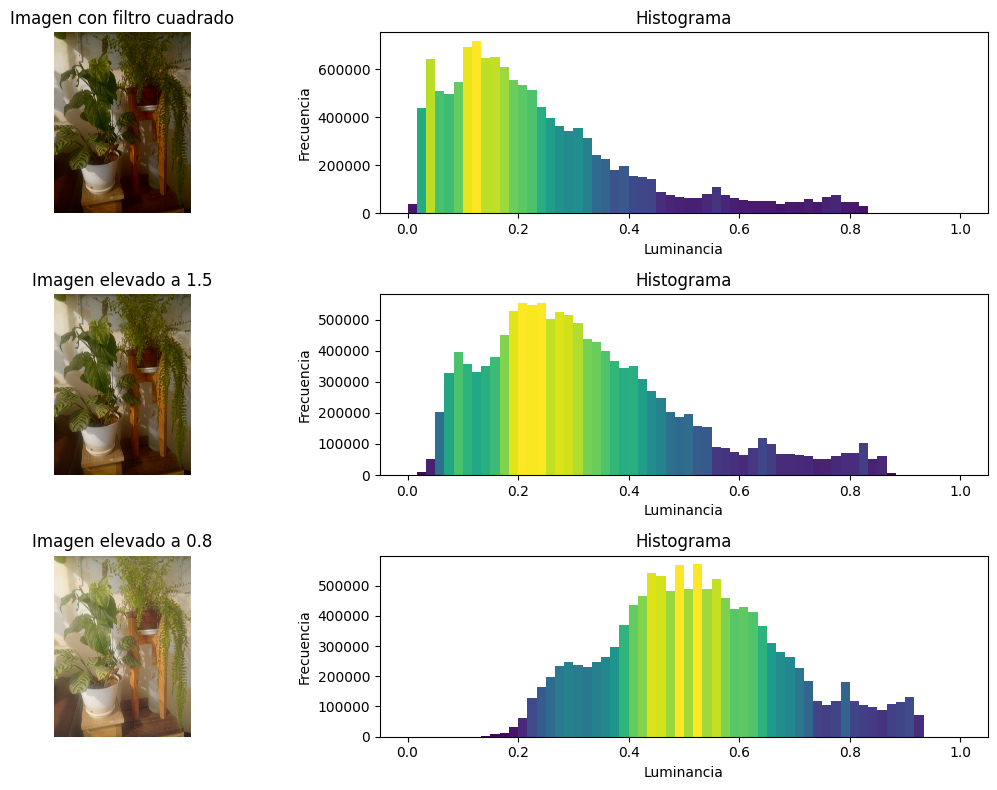

In [96]:

imagen_copy4=filtro_potencia(y1,2)
imagen_copy5=filtro_potencia(y1,1.5)
imagen_copy6=filtro_potencia(y1,0.8)

imagen_copy4_color=YIQaRGB(imagen_copy4,i2,q2)
imagen_copy5_color=YIQaRGB(imagen_copy5,i2,q2)
imagen_copy6_color=YIQaRGB(imagen_copy6,i2,q2)

plt.figure(figsize=(12,8))

plt.subplot(3,columnas,1)
plt.axis("off")
plt.title("Imagen con filtro cuadrado")
#plt.imshow(imagen_copy4,cmap="gray")
plt.imshow(imagen_copy4_color)

plt.subplot(3,columnas,2)
mostrar_histograma(imagen_copy4)

plt.subplot(3,columnas,3)
plt.axis("off")
plt.title("Imagen elevado a 1.5")
plt.imshow(imagen_copy5_color)

plt.subplot(3,columnas,4)
mostrar_histograma(imagen_copy5)

plt.subplot(3,columnas,5)
plt.axis("off")
plt.title("Imagen elevado a 0.8")
plt.imshow(imagen_copy6_color)

plt.subplot(3,columnas,6)
mostrar_histograma(imagen_copy6)
""""""
plt.tight_layout()
plt.show()